<img src=https://i.imgur.com/WKQ0nH2.jpg height=350>

# Setup and Context


### Introduction

Welcome to Boston Massachusetts in the 1970s! Imagine you're working for a real estate development company. Your company wants to value any residential project before they start. You are tasked with building a model that can provide a price estimate based on a home's characteristics like:
* The number of rooms
* The distance to employment centres
* How rich or poor the area is
* How many students there are per teacher in local schools etc

<img src=https://i.imgur.com/WfUSSP7.png height=350>

To accomplish your task you will:

1. Analyse and explore the Boston house price data
2. Split your data for training and testing
3. Run a Multivariable Regression
4. Evaluate how your model's coefficients and residuals
5. Use data transformation to improve your model performance
6. Use your model to estimate a property price

###  Import Statements


In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
# TODO: Add missing import statements

# Load the Data

The first column in the .csv file just has the row numbers, so it will be used as the index. 

In [2]:
data = pd.read_csv('boston.csv', index_col=0)

### Understand the Boston House Price Dataset

---------------------------

**Characteristics:**  

    :Number of Instances: 506 

    :Number of Attributes: 13 numeric/categorical predictive. The Median Value (attribute 14) is the target.

    :Attribute Information (in order):
        1. CRIM     per capita crime rate by town
        2. ZN       proportion of residential land zoned for lots over 25,000 sq.ft.
        3. INDUS    proportion of non-retail business acres per town
        4. CHAS     Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)
        5. NOX      nitric oxides concentration (parts per 10 million)
        6. RM       average number of rooms per dwelling
        7. AGE      proportion of owner-occupied units built prior to 1940
        8. DIS      weighted distances to five Boston employment centres
        9. RAD      index of accessibility to radial highways
        10. TAX      full-value property-tax rate per $10,000
        11. PTRATIO  pupil-teacher ratio by town
        12. B        1000(Bk - 0.63)^2 where Bk is the proportion of blacks by town
        13. LSTAT    % lower status of the population
        14. PRICE     Median value of owner-occupied homes in $1000's
        
    :Missing Attribute Values: None

    :Creator: Harrison, D. and Rubinfeld, D.L.

This is a copy of [UCI ML housing dataset](https://archive.ics.uci.edu/ml/machine-learning-databases/housing/). This dataset was taken from the StatLib library which is maintained at Carnegie Mellon University. You can find the [original research paper here](https://deepblue.lib.umich.edu/bitstream/handle/2027.42/22636/0000186.pdf?sequence=1&isAllowed=y). 


# Preliminary Data Exploration 🔎

In [3]:
data.shape

(506, 14)

In [4]:
data.columns

Index(['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX',
       'PTRATIO', 'B', 'LSTAT', 'PRICE'],
      dtype='object')

## Data Cleaning - Check for Missing Values and Duplicates

In [5]:
data.isna().sum()

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
PRICE      0
dtype: int64

In [6]:
data.duplicated().values.any()

False

## Descriptive Statistics

In [7]:
data.describe()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,PRICE
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


## Visualise the Features 

What do you notice in the distributions of the data? 

#### House Prices 💰

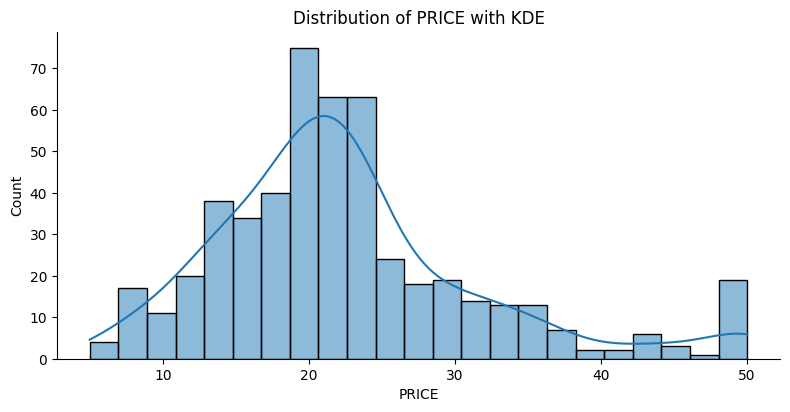

In [8]:
variables = ['PRICE']

for var in variables:
    sns.displot(data=data, x=var, kde=True, aspect=2, height=4)
    plt.title(f'Distribution of {var} with KDE')
    plt.show()

#### Distance to Employment - Length of Commute 🚗

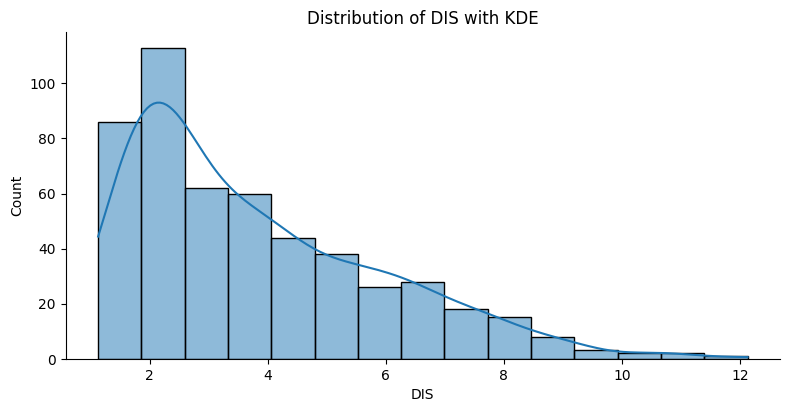

In [9]:
variables = ['DIS']

for var in variables:
    sns.displot(data=data, x=var, kde=True, aspect=2, height=4)
    plt.title(f'Distribution of {var} with KDE')
    plt.show()

#### Number of Rooms

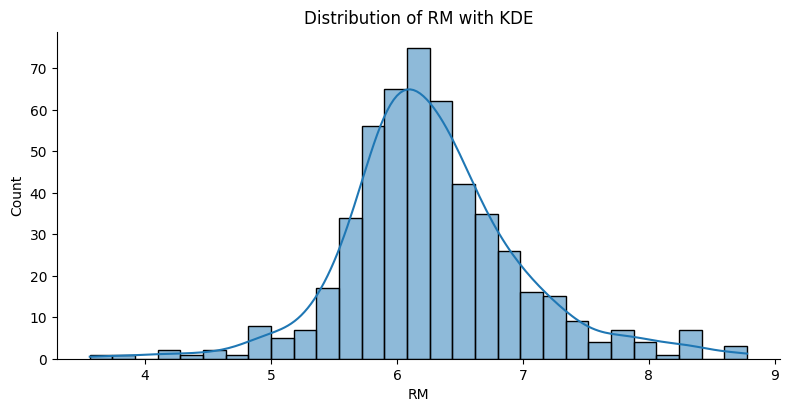

In [10]:
variables = ['RM']

for var in variables:
    sns.displot(data=data, x=var, kde=True, aspect=2, height=4)
    plt.title(f'Distribution of {var} with KDE')
    plt.show()

#### Access to Highways 🛣

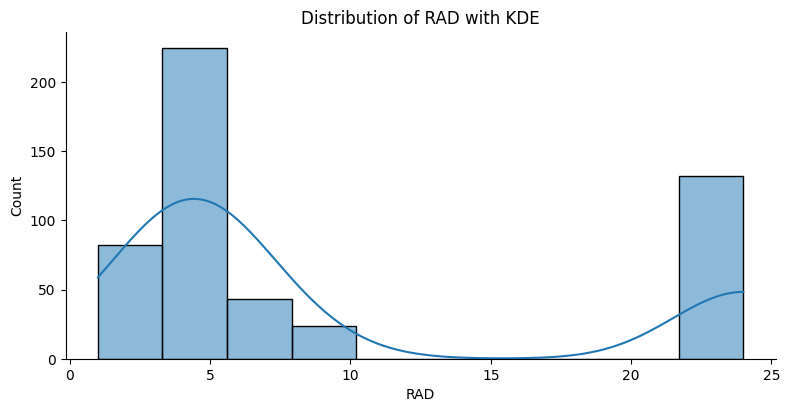

In [11]:
variables = ['RAD']

for var in variables:
    sns.displot(data=data, x=var, kde=True, aspect=2, height=4)
    plt.title(f'Distribution of {var} with KDE')
    plt.show()

#### Next to the River? ⛵️

In [12]:
chas_counts = data['CHAS'].value_counts()
bar=px.bar(chas_counts,x=['no','yes'],y=chas_counts.values,#color='CHAS',
       title='Next to Charles River?')
bar.update_layout(
    xaxis_title='Property Located Next to River?', yaxis_title='Number of Homes',
     width=900,    
    height=500 
)
bar.show()

<img src=https://i.imgur.com/b5UaBal.jpg height=350>

# Understand the Relationships in the Data

### Run a Pair Plot

In [13]:
# sns.pairplot(data)

Use [Seaborn's `.jointplot()`](https://seaborn.pydata.org/generated/seaborn.jointplot.html) to look at some of the relationships in more detail. Create a jointplot for:

* DIS and NOX
* INDUS vs NOX
* LSTAT vs RM
* LSTAT vs PRICE
* RM vs PRICE


#### Distance from Employment vs. Pollution

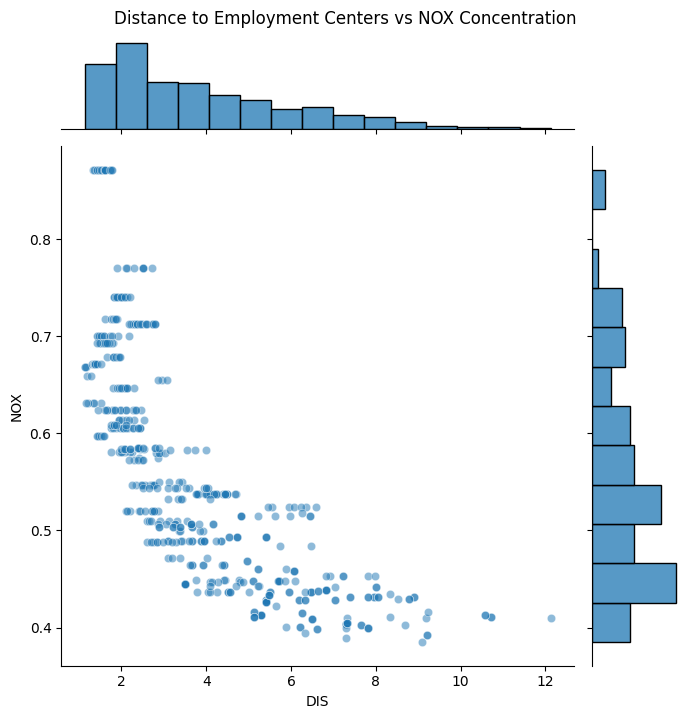

In [14]:
sns.jointplot(
    data=data, 
    x='DIS', 
    y='NOX',
    kind='scatter',
    joint_kws={'alpha': 0.5},
    height=7
)
plt.suptitle('Distance to Employment Centers vs NOX Concentration', y=1.02)
plt.show()

#### Proportion of Non-Retail Industry 🏭🏭🏭 versus Pollution 

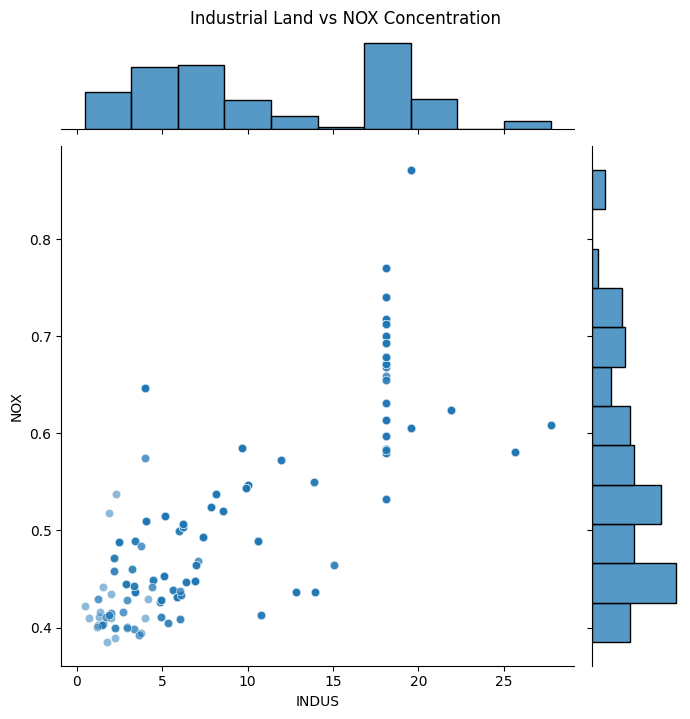

In [15]:
sns.jointplot(
    data=data, 
    x='INDUS', 
    y='NOX',
    joint_kws={'alpha': 0.5},
    height=7
)
plt.suptitle('Industrial Land vs NOX Concentration', y=1.02)
plt.show()

#### % of Lower Income Population vs Average Number of Rooms


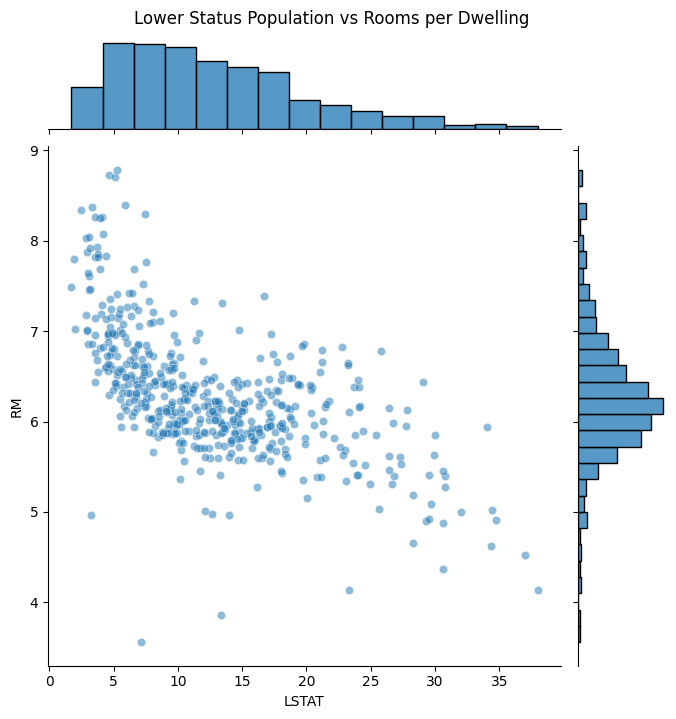

In [16]:
sns.jointplot(
    data=data, 
    x='LSTAT', 
    y='RM',
    joint_kws={'alpha': 0.5},
    height=7
)
plt.suptitle('Lower Status Population vs Rooms per Dwelling', y=1.02)
plt.show()

#### % of Lower Income Population versus Home Price


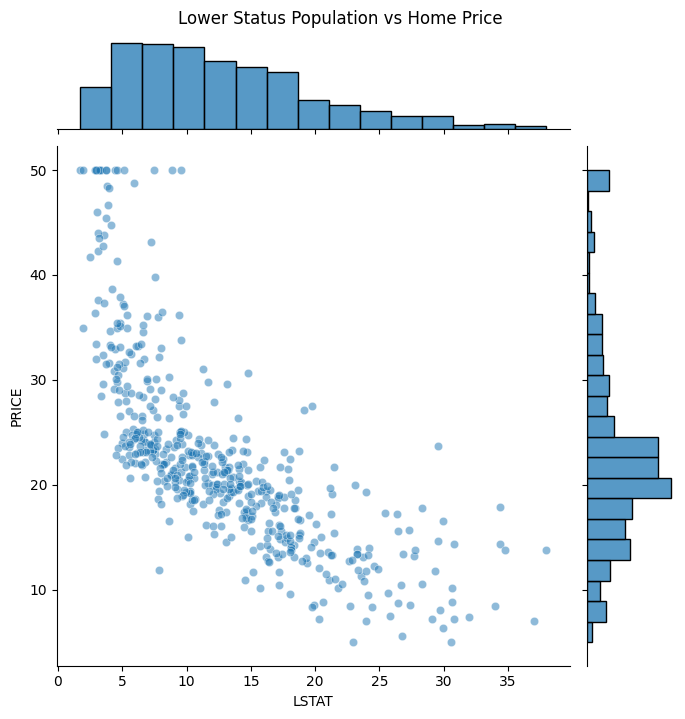

In [17]:
sns.jointplot(
    data=data, 
    x='LSTAT', 
    y='PRICE',
    joint_kws={'alpha': 0.5},
    height=7
)
plt.suptitle('Lower Status Population vs Home Price', y=1.02)
plt.show()


#### Number of Rooms versus Home Value

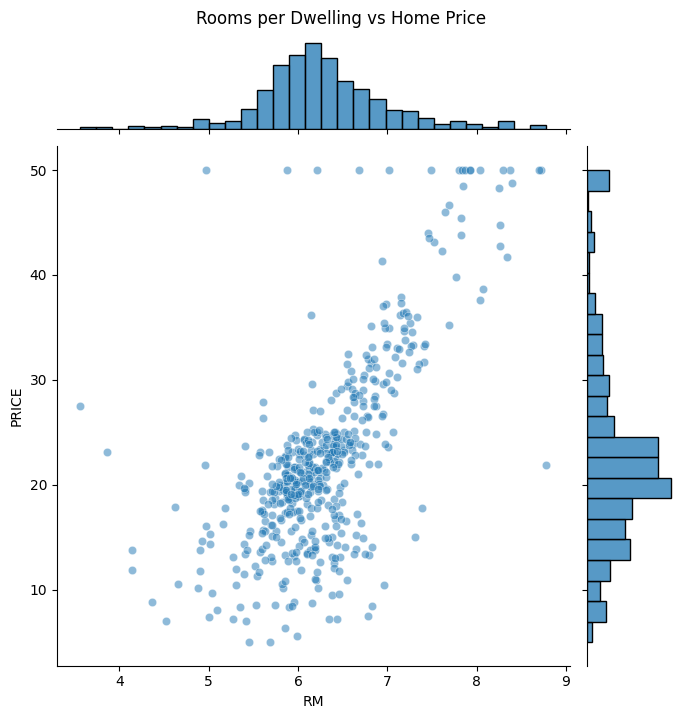

In [18]:
sns.jointplot(
    data=data, 
    x='RM', 
    y='PRICE',
    joint_kws={'alpha': 0.5},
    height=7
)
plt.suptitle('Rooms per Dwelling vs Home Price', y=1.02)
plt.show()

# Split Training & Test Dataset

We *can't* use all 506 entries in our dataset to train our model. The reason is that we want to evaluate our model on data that it hasn't seen yet (i.e., out-of-sample data). That way we can get a better idea of its performance in the real world. 


In [19]:
x=data.drop('PRICE',axis=1)
y=data['PRICE']
X_train, X_test, y_train, y_test = train_test_split(x,y,train_size=0.8,random_state=10)

# Multivariable Regression

$$ PR \hat ICE = \theta _0 + \theta _1 RM + \theta _2 NOX + \theta _3 DIS + \theta _4 CHAS ... + \theta _{13} LSTAT$$

### Run Your First Regression

In [20]:
regression=LinearRegression()
model=regression.fit(X_train,y_train)
print(model.intercept_)
print(model.coef_)

36.533051382824254
[-1.28180656e-01  6.31981786e-02 -7.57627602e-03  1.97451452e+00
 -1.62719890e+01  3.10845625e+00  1.62922153e-02 -1.48301360e+00
  3.03988206e-01 -1.20820710e-02 -8.20305699e-01  1.14189890e-02
 -5.81626431e-01]


In [21]:
print(model.score(X_train,y_train))

0.750121534530608


### Evaluate the Coefficients of the Model

Here we do a sense check on our regression coefficients. The first thing to look for is if the coefficients have the expected sign (positive or negative). 

In [22]:
coef_df=pd.DataFrame(model.coef_)
coef_df

,0
0,-0.128181
1,0.063198
2,-0.007576
3,1.974515
4,-16.271989
5,3.108456
6,0.016292
7,-1.483014
8,0.303988
9,-0.012082


### Analyse the Estimated Values & Regression Residuals

The next step is to evaluate our regression. How good our regression is depends not only on the r-squared. It also depends on the **residuals** - the difference between the model's predictions ($\hat y_i$) and the true values ($y_i$) inside `y_train`. 

```
predicted_values = regr.predict(X_train)
residuals = (y_train - predicted_values)
```

Create two scatter plots.

The first plot should be actual values (`y_train`) against the predicted value values: 

<img src=https://i.imgur.com/YMttBNV.png height=350>

The cyan line in the middle shows `y_train` against `y_train`. If the predictions had been 100% accurate then all the dots would be on this line. The further away the dots are from the line, the worse the prediction was.

The second plot should be the residuals against the predicted prices. Here's what we're looking for: 

<img src=https://i.imgur.com/HphsBsj.png height=350>



In [23]:
predicted_values = model.predict(X_train)
residuals = (y_train - predicted_values)

Text(0, 0.5, 'Predicted Prices 000s y^i')

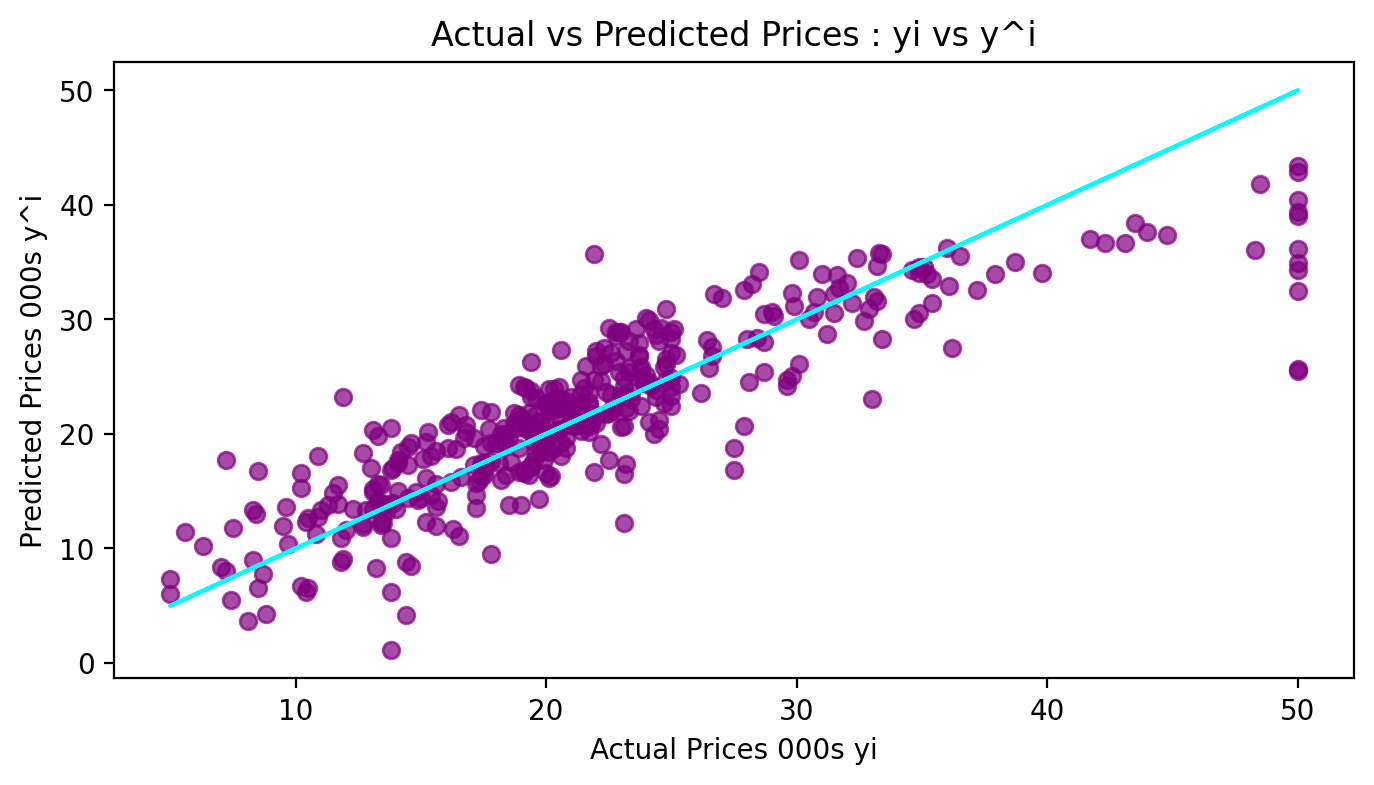

In [24]:
plt.figure(figsize=(8,4), dpi=200)
plt.plot(y_train,y_train,color='cyan')
plt.scatter(x=y_train,y=predicted_values,color='purple',alpha=0.7)

plt.title('Actual vs Predicted Prices : yi vs y^i')
plt.xlabel('Actual Prices 000s yi')
plt.ylabel('Predicted Prices 000s y^i')

Text(0.5, 0, 'Predicted Prices y^i')

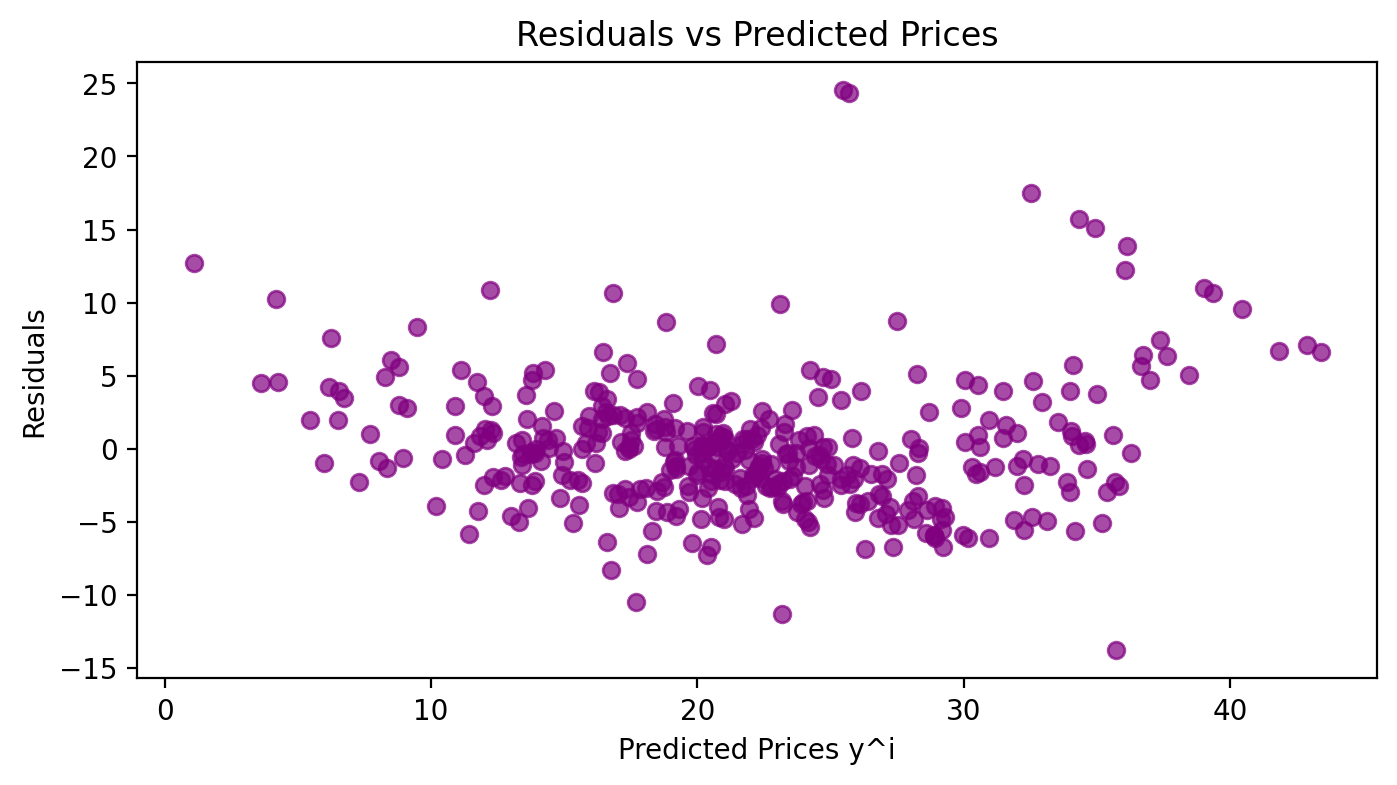

In [25]:
plt.figure(figsize=(8,4), dpi=200)
plt.scatter(x=predicted_values,y=residuals,color='purple',alpha=0.7)

plt.title('Residuals vs Predicted Prices')
plt.ylabel('Residuals')
plt.xlabel('Predicted Prices y^i')

Why do we want to look at the residuals? We want to check that they look random. Why? The residuals represent the errors of our model. If there's a pattern in our errors, then our model has a systematic bias.

We can analyse the distribution of the residuals. In particular, we're interested in the **skew** and the **mean**.

In an ideal case, what we want is something close to a normal distribution. A normal distribution has a skewness of 0 and a mean of 0. A skew of 0 means that the distribution is symmetrical - the bell curve is not lopsided or biased to one side. Here's what a normal distribution looks like: 

<img src=https://i.imgur.com/7QBqDtO.png height=400>


In [26]:
residuals_mean=residuals.mean()
residuals_skew=residuals.skew()
print(residuals_skew,residuals_mean)

1.4594428196679805 1.793944530879461e-15


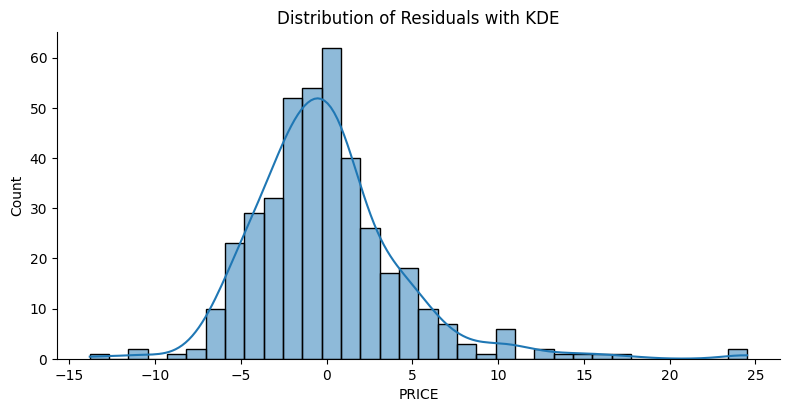

In [27]:
sns.displot(x=residuals, kde=True, aspect=2, height=4)
plt.title(f'Distribution of Residuals with KDE')
plt.show()

### Data Transformations for a Better Fit

We have two options at this point: 

1. Change our model entirely. Perhaps a linear model is not appropriate. 
2. Transform our data to make it fit better with our linear model. 

Let's try a data transformation approach. 

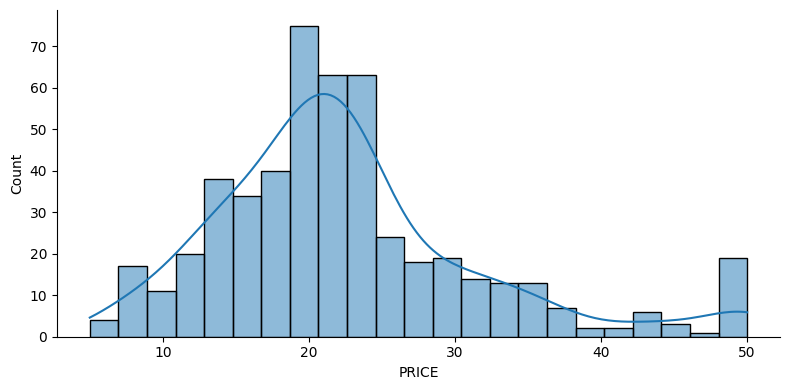

In [28]:
dis=sns.displot(x=data['PRICE'], kde=True, aspect=2, height=4)

In [29]:
data['PRICE'].skew()

1.1080984082549072

In [30]:
log_prices=np.log(data['PRICE'])

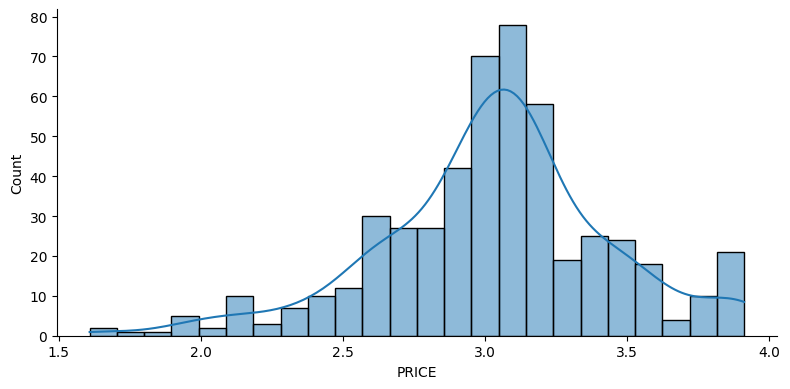

In [31]:
dis=sns.displot(x=log_prices, kde=True, aspect=2, height=4)

In [32]:
log_prices.skew()

-0.33032129530987864

In [33]:
# Definitely this has skew close to Zero.

#### How does the log transformation work?

Using a log transformation does not affect every price equally. Large prices are affected more than smaller prices in the dataset. Here's how the prices are "compressed" by the log transformation:

<img src=https://i.imgur.com/TH8sK1Q.png height=200>

We can see this when we plot the actual prices against the (transformed) log prices. 

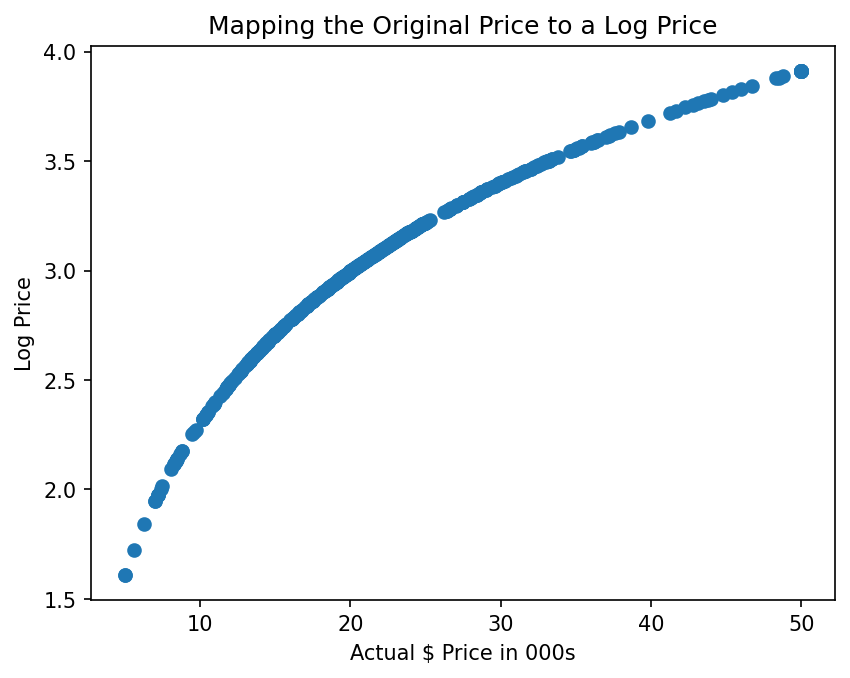

In [34]:
plt.figure(dpi=150)
plt.scatter(data.PRICE, np.log(data.PRICE))

plt.title('Mapping the Original Price to a Log Price')
plt.ylabel('Log Price')
plt.xlabel('Actual $ Price in 000s')
plt.show()

## Regression using Log Prices

Using log prices instead, our model has changed to:

$$ \log (PR \hat ICE) = \theta _0 + \theta _1 RM + \theta _2 NOX + \theta_3 DIS + \theta _4 CHAS + ... + \theta _{13} LSTAT $$



In [35]:
X_train2,X_test2,y_train2,y_test2=train_test_split(x,log_prices,train_size=0.8,random_state=10)

In [36]:
model2=LinearRegression()
model2.fit(X_train2,y_train2)

LinearRegression()

In [37]:
model2.score(X_train2,y_train2)

# Yes...we have improved...

0.7930234826697584

## Evaluating Coefficients with Log Prices

In [38]:
new_coef_df=pd.DataFrame(model2.coef_)
new_coef_df

,0
0,-0.010672
1,0.001579
2,0.002030
3,0.080331
4,-0.704068
5,0.073404
6,0.000763
7,-0.047633
8,0.014565
9,-0.000645


## Regression with Log Prices & Residual Plots


In [39]:
predicted_values2 = model2.predict(X_train2)
residuals2 = (y_train2 - predicted_values2)

Text(0, 0.5, 'Predicted Prices 000s y^i')

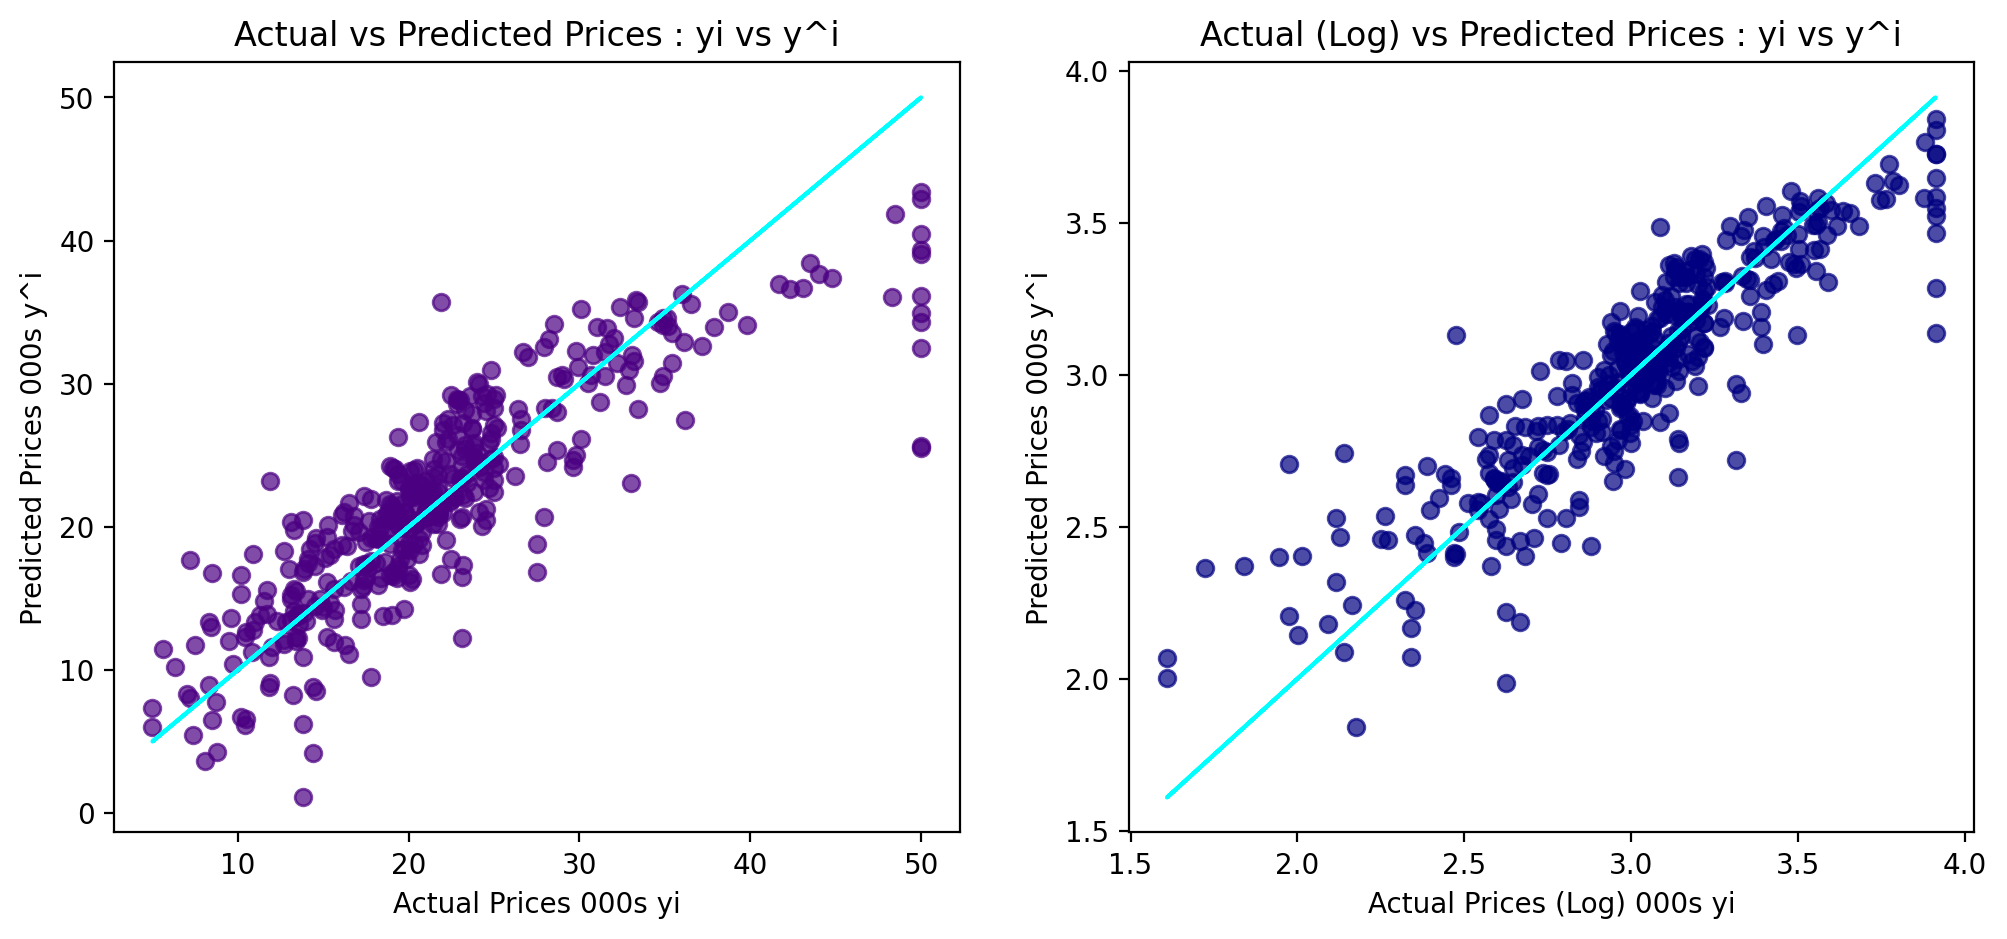

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=200)

axes[0].plot(y_train,y_train,color='cyan')
axes[0].scatter(x=y_train,y=predicted_values,color='indigo',alpha=0.7)
axes[0].set_title('Actual vs Predicted Prices : yi vs y^i')
axes[0].set_xlabel('Actual Prices 000s yi')
axes[0].set_ylabel('Predicted Prices 000s y^i')

axes[1].plot(y_train2,y_train2,color='cyan')
axes[1].scatter(x=y_train2,y=predicted_values2,color='navy',alpha=0.7)
axes[1].set_title('Actual (Log) vs Predicted Prices : yi vs y^i')
axes[1].set_xlabel('Actual Prices (Log) 000s yi')
axes[1].set_ylabel('Predicted Prices 000s y^i')


Text(0, 0.5, 'Residuals (Log)')

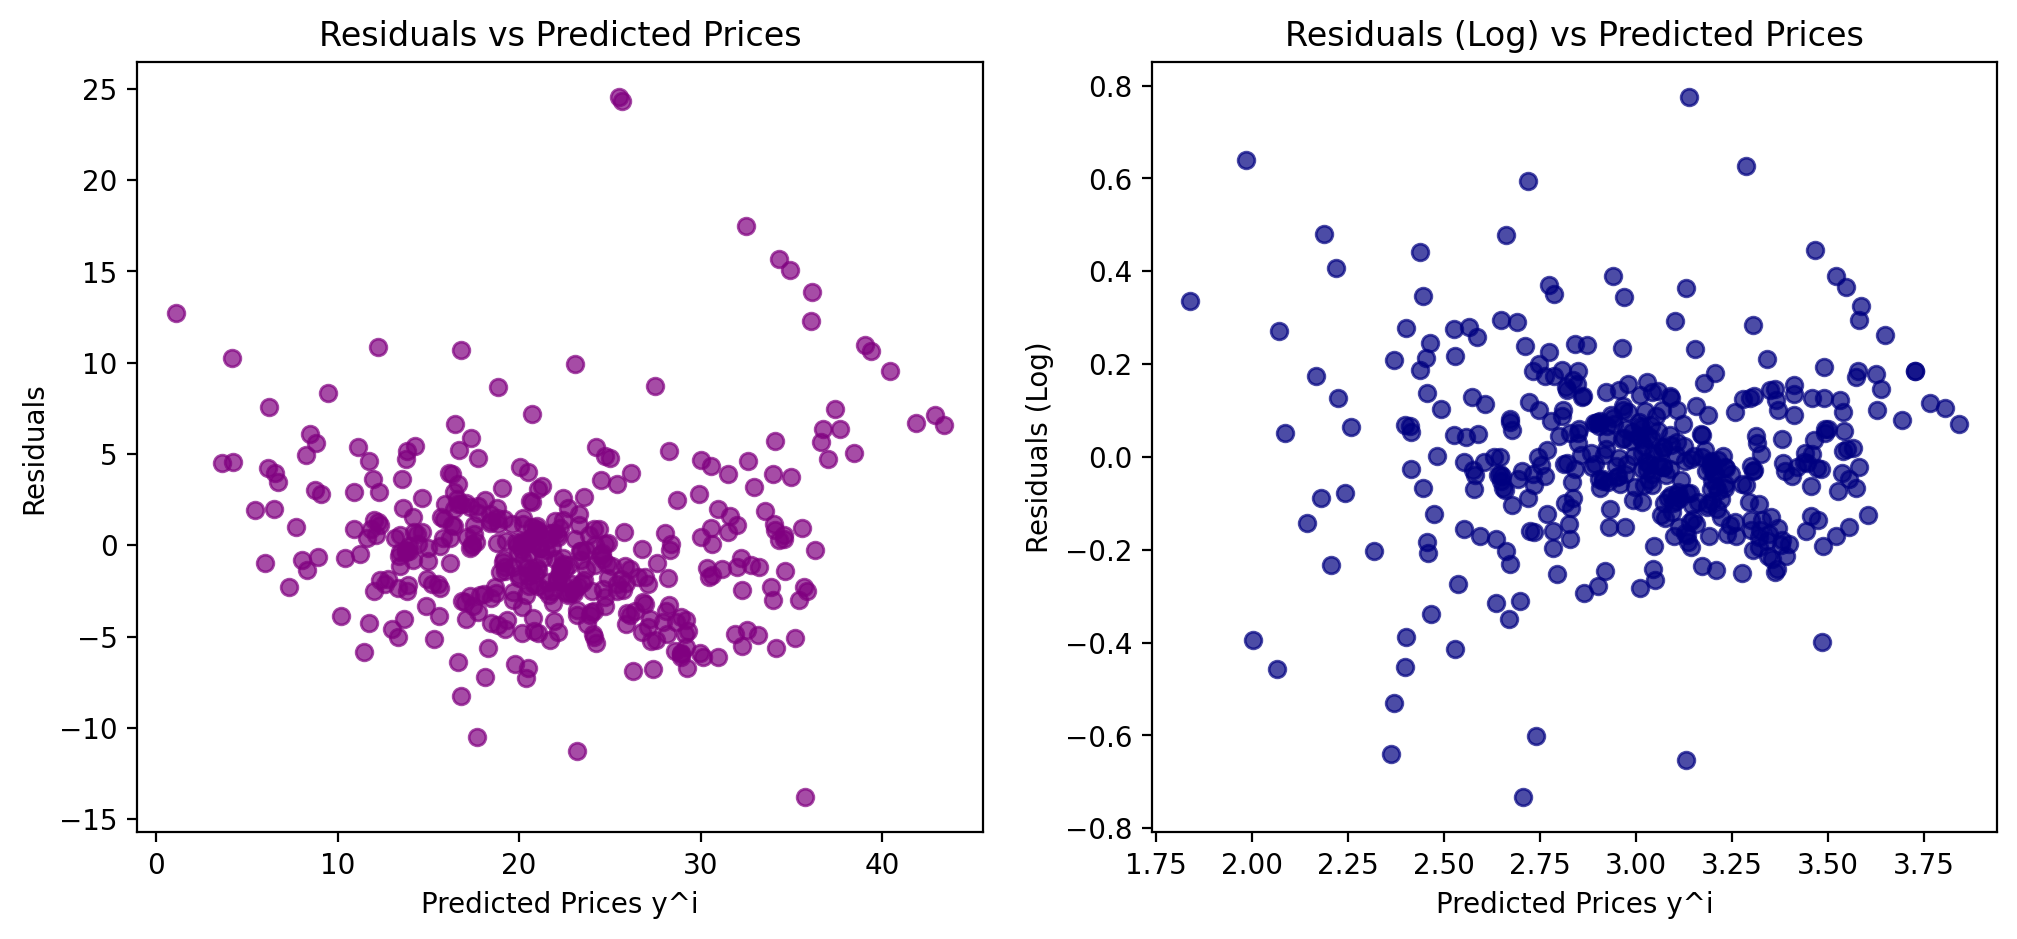

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=200)

axes[0].scatter(x=predicted_values,y=residuals,color='purple',alpha=0.7)
axes[0].set_title('Residuals vs Predicted Prices')
axes[0].set_xlabel('Predicted Prices y^i')
axes[0].set_ylabel('Residuals')

axes[1].scatter(x=predicted_values2,y=residuals2,color='navy',alpha=0.7)
axes[1].set_title('Residuals (Log) vs Predicted Prices')
axes[1].set_xlabel('Predicted Prices y^i')
axes[1].set_ylabel('Residuals (Log)')

In [42]:
mean2=residuals2.mean()
skew2=residuals2.skew()
print(mean2,skew2)

2.2479268171865794e-16 0.09299942594122727


# Compare Out of Sample Performance

The real test is how our model performs on data that it has not "seen" yet. This is where our `X_test` comes in. 

Compare the r-squared of the two models on the test dataset. Which model does better? Is the r-squared higher or lower than for the training dataset? Why?

In [43]:
print(model.score(X_test,y_test),model2.score(X_test2,y_test2),sep='\n')

# model1=0.67
# model2=0.74

0.6709339839115627
0.7446922306260733


# Predict a Property's Value using the Regression Coefficients

Our preferred model now has an equation that looks like this:

$$ \log (PR \hat ICE) = \theta _0 + \theta _1 RM + \theta _2 NOX + \theta_3 DIS + \theta _4 CHAS + ... + \theta _{13} LSTAT $$

The average property has the mean value for all its charactistics:

In [44]:
# Starting Point: Average Values in the Dataset
features = data.drop(['PRICE'], axis=1)
average_vals = features.mean().values
property_stats = pd.DataFrame(data=average_vals.reshape(1, len(features.columns)), 
                              columns=features.columns)
property_stats

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
0,3.613524,11.363636,11.136779,0.06917,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063


In [45]:
log_price_estimate=model2.predict(property_stats)
normal_price=np.exp(log_price_estimate[0])
print(log_price_estimate[0],normal_price,sep='\n')

3.0302872305633954
20.703178321023927


# Predicting with Defined Values

In [46]:
# Defined Property Characteristics
next_to_river = True
nr_rooms = 8
students_per_classroom = 20 
distance_to_town = 5
pollution = data.NOX.quantile(q=0.75) # high
amount_of_poverty =  data.LSTAT.quantile(q=0.25) # low

In [47]:
property_stats['CHAS'] = int(next_to_river)
property_stats['RM'] = nr_rooms
property_stats['PTRATIO'] = students_per_classroom
property_stats['DIS'] = distance_to_town
property_stats['NOX'] = pollution
property_stats['LSTAT'] = amount_of_poverty

log_estimate = model2.predict(property_stats)[0]
dollar_estimate = np.exp(log_estimate) * 1000  # PRICE is in $1000s
print(log_estimate, dollar_estimate)

3.2500653694409225 25792.025872399023


# Learning Points
Well done! 

Today we've learned

How to quickly spot relationships in a dataset using Seaborn's .pairplot().

How to split the data into a training and testing dataset to better evaluate a model's performance.

How to run a multivariable regression.

How to evaluate that regression-based on the sign of its coefficients.

How to analyse and look for patterns in a model's residuals.

How to improve a regression model using (a log) data transformation.

How to specify your own values for various features and use your model to make a prediction.